---
title: "Issued 31 October 2023: the next three dekads"
subtitle: "Subseasonal rainfall forecasts for Indonesia at 0.05°, from GEFSv12 issued at the end of each dekad and calibrated with CCA and PCR through CPT"
description: "Forecast total rainfall for the next one, two and three dekads from each issue date in late 2023, using GEFSv12 calibrated with CCA and PCR against the CHIRPS v3.0 dekad product at its native 0.05° grid, and measure skill by lead over October-December 2000-2018."
execute:
  enabled: false
---

At the end of every dekad (*dasarian*: days 1-10, 11-20 and 21 to the end of a
month) a forecaster can ask how much rain will fall in **each of the next three
dekads**. Dekads are the unit BMKG, Indonesia's meteorological agency, uses for its
rainfall early warnings. This notebook builds that forecast from **GEFSv12**,
calibrated with CCA and PCR through CPT against the **CHIRPS v3.0 dekad product at
its native 0.05° grid**, about 61,000 pixels over Indonesia.

The story page opens on the forecast issued on **31 October 2023**, for the three
dekads of November, the same moment as the monthly and seasonal cases. The skill of
each lead is measured over every October-December dekad of 2000-2018, and every
2023 issue date is kept so the forecasts can be compared with what happened.

::: {.callout-note title="What you need to run this page"}
The full PyCPT environment with its CPT engine; the CHIRPS v3.0 dekadal archive used
throughout the tutorial; and internet access the first time for about 290 GEFSv12
files from the IRI Data Library, no key needed. At 0.05° one CPT fit takes tens of
minutes, so the six fits run in parallel, one process each.
:::

## 1. Issue dates, leads and training starts

**In real time** a forecast is issued on the last day of a dekad, from the GEFSv12
run started at 00 UTC that day. Dekad +1 begins the next day, dekad +2 eleven or
twelve days later, dekad +3 twenty-one or twenty-two days later. GEFSv12 runs every
day, so the 2023 forecasts use exactly these issue dates.

**For training**, GEFSv12's hindcasts (2000-2018) start only on Wednesdays. For each
October-December target dekad and each lead, the training sample uses the one
Wednesday whose start falls in a 7-day window around the real-time offset. Every
window holds exactly one Wednesday, so all three leads are trained on the same 171
target dekads (9 per year) and scored on the same targets. Lead 1 is the one
compromise: its training starts are 1-7 days before the target, its real-time start
1 day before, so training is on average slightly harder than real use. A fourth
dekad would need model days beyond 35. The design comes from the tutorial's
[GEFS download script](https://github.com/bennyistanto/pycpt-tutorial/blob/main/research/scripts/download_gefs_dekads.py),
which the cell imports so the two cannot disagree.

In [1]:
from pathlib import Path
import datetime as dt
import gzip
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
import xarray as xr
import cartopy.io.shapereader as shapereader

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
if repo is None:
    raise FileNotFoundError("Run this notebook inside the tutorial repository or kit.")
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "research/scripts"))
from pycpt_tutorial.export import save_netcdf
from pycpt_tutorial import figures
import download_gefs_dekads as gefs_source      # request, check and download helpers
import weekly_fits                              # parallel CPT fits (shared with the weekly and pentad cases)
figures.use_style()

case_root = Path.home() / "PyCPT" / "indonesia-ond-2023-dekads-005"
daily_dir = Path("/mnt/e/temp/chirps/daily-idn")
leads = list(gefs_source.WINDOWS)                # 1 to 3
lead_names = {lead: f"Dekad +{lead}" for lead in leads}
training_years = list(gefs_source.TRAINING_YEARS)
settings = dict(x_eof_modes=(3, 3), validation="CROSSVALIDATION", crossvalidation_window=17,
                synchronous_predictors=True, transform_predictand=None, tailoring=None,
                drymask_threshold=None, skillmask_threshold=None)
cca_settings = dict(settings, y_eof_modes=(3, 3), cca_modes=(2, 2))
workers = 6

design = pd.DataFrame(gefs_source.design()).rename(columns={"dekad": "target"})
design["issued"] = design["start"]                      # dekad issue dates use that day's run
for c in ["target", "end", "issued", "start"]:
    design[c] = pd.to_datetime(design[c])
print(f"{design[design.kind == 'hindcast'].start.nunique()} hindcast starts, {design[design.kind == 'forecast'].issued.nunique()} issue dates in 2023; "
      f"target lengths (days): {design[design.lead == 1].days.value_counts().sort_index().to_dict()}")
table = (design.groupby(["kind", "lead"])
         .agg(targets=("target", "size"), first_offset=("first_day", "min"), last_offset=("first_day", "max"), latest_model_day=("last_day", "max")))
table["training window (days)"] = [f"{gefs_source.WINDOWS[lead][0]}-{gefs_source.WINDOWS[lead][1]}" for _, lead in table.index]
table

278 hindcast starts, 11 issue dates in 2023; target lengths (days): {10: 140, 11: 40}


targets  first_offset  last_offset  latest_model_day  \
kind     lead                                                         
forecast 1           9             1            1                11   
         2           9            11           12                21   
         3           9            21           22                31   
hindcast 1         171             1            7                17   
         2         171             8           14                24   
         3         171            18           24                34   

              training window (days)  
kind     lead                         
forecast 1                       1-7  
         2                      8-14  
         3                     18-24  
hindcast 1                       1-7  
         2                      8-14  
         3                     18-24

## 2. Observations: CHIRPS v3.0 dekads at 0.05°

The predictand is the CHIRPS v3.0 **dekad product** from the local archive used
throughout the tutorial, kept at its native 0.05° grid. The archive stores each
dekad's time bounds; the cell checks that every October-December target in the
design has the same first day and length there before using it. The box is the one of
the weekly and pentad cases, so all three subseasonal cases share one pixel grid. The
predictand is every pixel whose centre lies inside Indonesia (Natural Earth 1:10m)
with data in all 171 training dekads.

In [2]:
chirps3_file = Path("/mnt/e/temp/chirps/dekad/wld_cli_chirps3_dekad_1981_2025.nc")
source = xr.open_dataset(chirps3_file)
print("Variable attributes:", {k: source.precip.attrs[k] for k in ("units", "cell_methods", "comment")})
targets = design[design.lead == 1].sort_values("target").reset_index(drop=True)
for lead in leads:                               # every lead uses the same target dekads
    assert (design[design.lead == lead].sort_values("target").target.values == targets.target.values).all()
stored = pd.DatetimeIndex(source.time_bnds.sel(time=targets.target.values).values.ravel()).values.reshape(-1, 2)
assert (stored[:, 0] == targets.target.values).all() and (stored[:, 1] == targets.end.values).all()
print(f"All {len(targets)} target dekads found, with stored bounds equal to the design")

start = time.monotonic()
obs = (source.precip.sel(time=targets.target.values, lon=slice(93.95, 142.0), lat=slice(-12.0, 7.05)).load()
       .rename({"time": "T", "lat": "Y", "lon": "X"}))
obs = obs.assign_coords(Y=np.round(obs.Y.values.astype(float), 3), X=np.round(obs.X.values.astype(float), 3)).sortby("Y", ascending=False)
print(f"Read {dict(obs.sizes)} in {time.monotonic() - start:.0f} s; negative values: {int((obs < 0).sum())}; "
      f"grid {obs.X.values[0]}-{obs.X.values[-1]} E, {obs.Y.values[-1]}-{obs.Y.values[0]} N")

records = shapereader.Reader(shapereader.natural_earth("10m", "cultural", "admin_0_countries")).records()
indonesia = next(r.geometry for r in records if r.attributes["ADM0_A3"] == "IDN")
shapely.prepare(indonesia)
lon2d, lat2d = np.meshgrid(obs.X, obs.Y)
land = xr.DataArray(shapely.contains_xy(indonesia, lon2d, lat2d), dims=("Y", "X"), coords={"Y": obs.Y, "X": obs.X})
train = (targets.kind == "hindcast").values
mask = land & obs.isel(T=train).notnull().all("T")
weights = np.cos(np.deg2rad(mask["Y"])) * mask
print(f"Pixels inside Indonesia {int(land.sum()):,}, with data in every training dekad {int(mask.sum()):,}")

Variable attributes: {'units': 'mm', 'cell_methods': 'time: sum', 'comment': 'Exact zeros are preserved, for a zero-inflated distribution fit. NaN marks no data.'}


All 180 target dekads found, with stored bounds equal to the design


Read {'T': 180, 'Y': 381, 'X': 961} in 52 s; negative values: 0; grid 93.975-141.975 E, -11.975-7.025 N


Pixels inside Indonesia 61,192, with data in every training dekad 61,190


A check against the pentad product of the pentad case: two pentads make a dekad, so
for the dekads of three years the archive should equal their sum.

In [3]:
pentad_dir = Path("/mnt/e/temp/chirps/pentad-idn")
for year, first in [(2005, "2005-10-01"), (2012, "2012-11-11"), (2023, "2023-12-21")]:
    with xr.open_dataset(pentad_dir / f"chirps3_pentad_idn_{year}.nc") as p:
        bounds = pd.DatetimeIndex(source.time_bnds.sel(time=first).values)
        firsts = pd.DatetimeIndex(p.time.values)
        pick = firsts[(firsts >= bounds[0]) & (firsts < bounds[1])]
        two = p.precip.sel(time=pick).sum("time", skipna=False).load().rename({"lat": "Y", "lon": "X"})
    two = two.assign_coords(Y=np.round(two.Y.values.astype(float), 3), X=np.round(two.X.values.astype(float), 3)).reindex_like(obs)
    gap = abs(two - obs.sel(T=first)).where(land)
    print(f"dekad {first} = pentads {', '.join(f'{d:%d %b}' for d in pick)}: largest difference over Indonesia {float(gap.max()):.4f} mm")

dekad 2005-10-01 = pentads 01 Oct, 06 Oct: largest difference over Indonesia 0.0000 mm


dekad 2012-11-11 = pentads 11 Nov, 16 Nov: largest difference over Indonesia 0.0000 mm


dekad 2023-12-21 = pentads 21 Dec, 26 Dec: largest difference over Indonesia 0.0000 mm


## 3. Model: daily GEFSv12 to dekad totals

Each start is one request to the IRI Data Library for the predictor box
85-155°E, 20°S-20°N, all members and daily slots; files already on disk are reused
when they cover every model day their targets need (most were downloaded for the
pentad and weekly cases). Hindcasts store each day's amount (kg m⁻², which is mm),
real-time forecasts a rate (kg m⁻² s⁻¹), converted with 86,400 seconds per day.
Model day d after the start is slot L = d + 0.5. A dekad total is the sum of the
target's days, then the mean over members.

In [4]:
raw_dir = case_root.parent / "indonesia-ond-2023-dekads" / "gefs"
need = gefs_source.needed_starts()
fetched = sum(gefs_source.ensure(raw_dir, kind, s, last_day) > 0 for (kind, s), last_day in need.items())
print(f"{len(need)} starts checked; downloaded now: {fetched}")

factor = {"hindcast": 1.0, "forecast": 86400.0}
totals, missing, negative = {}, 0, 0
for (kind, s), rows in design.groupby(["kind", "start"]):
    with xr.open_dataset(gefs_source.path_for(raw_dir, kind, s.date()), decode_timedelta=False) as ds:
        pr = ds["pr"].isel(S=0, drop=True).load()
    for r in rows.itertuples():
        d = pr.sel(L=np.arange(r.first_day, r.first_day + r.days) + 0.5)
        missing += int((~np.isfinite(d)).sum())
        negative += int((d < 0).sum())
        totals[r.lead, r.target] = (d * factor[kind]).sum("L", skipna=False).mean("M", skipna=False)
assert missing == 0 and negative == 0
gefs = {lead: xr.concat([totals[lead, t] for t in targets.target], "T").assign_coords(T=targets.target.values)
        .sortby("Y", ascending=False) for lead in leads}
print(f"GEFS totals per lead {dict(gefs[1].sizes)}; missing values {missing}, negative values {negative}")

289 starts checked; downloaded now: 0


GEFS totals per lead {'T': 180, 'Y': 41, 'X': 71}; missing values 0, negative values 0


## 4. Anomalies, and what CPT needs

Rainfall rises through October-December, so model and observations are turned into
**anomalies** from the 2000-2018 mean of the **same calendar dekad** (and, for the
model, the same lead). The same means are
subtracted from the 2023 values, and the observed mean is added back at the end to
give a forecast **total**. These means include the year held out in
cross-validation; for correlations that makes no difference (leaving a year out
multiplies every anomaly of that dekad by the same factor, 19/18), and its effect
inside CPT's fits was not measured.

CPT needs three adjustments, each found by a failed run while preparing the case: placeholder annual dates
in the original order (cross-validation depends only on the order), the field name
`anomaly` (CPT refuses negative values under precipitation names), and latitudes
from north to south. The cross-validation window of 17 leaves out the held-out
dekad and 8 on each side, about a whole season, so a training fit never sees
another dekad of the same season.

In [5]:
key = pd.DatetimeIndex(targets.target).strftime("%m-%d")
train_keys = key[train]
W = np.zeros((len(key), int(train.sum())))
for i, k in enumerate(key):
    same = np.flatnonzero(train_keys == k)
    W[i, same] = 1 / len(same)
assert ((W > 0).sum(1) == len(training_years)).all()


def apply_weights(field):
    a = field.isel(T=train).transpose("T", ...).values
    clim = (W @ np.nan_to_num(a.reshape(a.shape[0], -1))).reshape((W.shape[0],) + a.shape[1:])
    return field.copy(data=clim.astype("float32"))


y_clim = apply_weights(obs).where(mask)
y_anom = (obs - y_clim).where(mask)
x_anom = {lead: gefs[lead] - apply_weights(gefs[lead]) for lead in leads}
area = lambda f: float(f.where(mask).weighted(weights).mean(("Y", "X")))
season = y_clim.isel(T=np.flatnonzero(train)[:9]).weighted(weights).mean(("Y", "X"))
print("2000-2018 mean dekad rainfall over Indonesian pixels (mm):",
      dict(zip(key[:9], np.round(season.values, 1).tolist())))


def cpt_ready(a, first_year):
    years = first_year + np.arange(a.sizes["T"])
    a = a.drop_vars([c for c in a.coords if c not in ("T", "Y", "X")]).transpose("T", "Y", "X")
    a = a.assign_coords(T=pd.to_datetime([f"{y}-10-05" for y in years]),
                        Ti=("T", pd.to_datetime([f"{y}-10-01" for y in years])),
                        Tf=("T", pd.to_datetime([f"{y}-10-10" for y in years])))
    a = a.rename("anomaly")
    a.attrs = {"units": "mm", "missing": -999.0}
    return a


inputs_dir = case_root / "inputs"
inputs_dir.mkdir(parents=True, exist_ok=True)
paths = {"Y": inputs_dir / "Y.nc"}
cpt_ready(y_anom.isel(T=train), 1680).to_netcdf(paths["Y"])
for lead in leads:
    paths["X", lead] = inputs_dir / f"X-lead{lead}.nc"
    paths["F", lead] = inputs_dir / f"F-lead{lead}.nc"
    cpt_ready(x_anom[lead].isel(T=train), 1680).to_netcdf(paths["X", lead])
    cpt_ready(x_anom[lead].isel(T=~train), 2040).to_netcdf(paths["F", lead])
print({str(k): f"{p.stat().st_size / 1e6:.0f} MB" for k, p in paths.items()})

2000-2018 mean dekad rainfall over Indonesian pixels (mm): {'10-01': 75.2, '10-11': 75.1, '10-21': 93.5, '11-01': 89.2, '11-11': 98.3, '11-21': 98.9, '12-01': 98.8, '12-11': 97.5, '12-21': 111.4}


{'Y': '250 MB', "('X', 1)": '2 MB', "('F', 1)": '0 MB', "('X', 2)": '2 MB', "('F', 2)": '0 MB', "('X', 3)": '2 MB', "('F', 3)": '0 MB'}


## 5. Six fits, in parallel

CCA (3 predictor and 3 predictand EOFs, 2 CCA modes) and PCR (3 predictor EOFs) for
each of the three leads, through `cptcore`, the layer PyCPT's `evaluate_models`
calls. Each fit runs in its own process (`weekly_fits.py` in the tutorial's research
scripts, shared with the weekly and pentad cases) and keeps only the forecast and skill maps; a
fit is reused only if its saved result was made from identical input values and
settings. Each worker also recomputes the correlation from CPT's own cross-validated
hindcasts and stores the largest difference from CPT's map.

In [6]:
jobs = [dict(lead=lead, method=method, folder=str(case_root / f"fit-lead{lead}-{method.lower()}"),
             inputs={"X": str(paths["X", lead]), "Y": str(paths["Y"]), "F": str(paths["F", lead])},
             settings=cca_settings if method == "CCA" else settings)
        for lead in leads for method in ["CCA", "PCR"]]
start = time.monotonic()
done = weekly_fits.run_all(jobs, workers=workers)
print(f"All fits finished in {(time.monotonic() - start) / 60:.0f} min wall time")
results, rows = {}, []
for d in done:
    r = xr.open_dataset(d["path"]).load()
    results[d["lead"], d["method"]] = r
    rows.append({"lead": lead_names[d["lead"]], "method": d["method"], "fit (min)": round(r.attrs["fit_seconds"] / 60, 1),
                 "reused": d["reused"], "hindcast values below 0 (%)": round(r.attrs["hindcast_values_below_zero_percent"], 1),
                 "largest gap, CPT vs recomputed correlation": r.attrs["largest_gap_cpt_vs_recomputed_pearson"]})
pd.DataFrame(rows).set_index(["lead", "method"])

All fits finished in 0 min wall time


fit (min)  reused  hindcast values below 0 (%)  \
lead     method                                                   
Dekad +1 CCA          38.0    True                         49.9   
         PCR          13.2    True                         50.0   
Dekad +2 CCA          38.4    True                         50.3   
         PCR          14.0    True                         50.5   
Dekad +3 CCA          31.6    True                         52.0   
         PCR          13.1    True                         51.7   

                 largest gap, CPT vs recomputed correlation  
lead     method                                              
Dekad +1 CCA                                   9.183110e-07  
         PCR                                   9.443746e-07  
Dekad +2 CCA                                   9.861062e-07  
         PCR                                   8.790783e-07  
Dekad +3 CCA                                   8.309026e-07  
         PCR                                   8.377209e-07

Negative hindcast values show the anomalies were not clipped at zero, and a gap near
zero shows CPT's correlation map is the correlation of its own cross-validated
hindcasts.

## 6. Skill by lead

Cross-validated scores over the 171 training dekads, as area-weighted means over
the Indonesian pixels (weights: cosine of latitude):

- **Pearson correlation** of hindcast and observed anomalies; 0 is no linear relationship.
- **2AFC**: the chance (in %) that the hindcasts rank two different dekads in the observed order; 50% is no skill.
- **ROC area** for below- and above-normal dekads; 0.5 is no skill.

The **raw GEFS** baseline is the model's own anomaly, interpolated linearly from 1°
to the pixel centres, correlated with the observed anomalies. It involves no
fitting, so it pays none of the cost that cross-validation charges the calibrated
forecasts.

In [7]:
def clean(a):
    return a.where(a > -999).reindex(Y=mask["Y"], X=mask["X"], method="nearest", tolerance=1e-4).where(mask)


def pearson(a, b):
    a, b = a - a.mean("T"), b - b.mean("T")
    return (a * b).sum("T") / np.sqrt((a * a).sum("T") * (b * b).sum("T"))


raw_pearson = {}
for lead in leads:
    xa = x_anom[lead].isel(T=train).interp(Y=mask["Y"], X=mask["X"], method="linear")
    raw_pearson[lead] = pearson(xa, y_anom.isel(T=train)).where(mask)

rows = []
for (lead, method), r in results.items():
    rows.append({"lead": lead, "name": lead_names[lead], "method": method,
                 "Pearson": area(clean(r.skill_pearson)), "2AFC (%)": area(clean(r.skill_two_alternative_forced_choice)),
                 "ROC below normal": area(clean(r.skill_roc_area_below_normal)), "ROC above normal": area(clean(r.skill_roc_area_above_normal))})
for lead in leads:
    rows.append({"lead": lead, "name": lead_names[lead], "method": "raw GEFS", "Pearson": area(raw_pearson[lead])})
skill_by_lead = pd.DataFrame(rows).set_index(["lead", "method"]).sort_index()
skill_by_lead.round(3)

name  Pearson  2AFC (%)  ROC below normal  ROC above normal
lead method                                                                   
1    CCA       Dekad +1    0.351    62.681             0.691             0.672
     PCR       Dekad +1    0.344    62.511             0.687             0.670
     raw GEFS  Dekad +1    0.420       NaN               NaN               NaN
2    CCA       Dekad +2    0.308    60.835             0.663             0.650
     PCR       Dekad +2    0.306    60.864             0.662             0.651
     raw GEFS  Dekad +2    0.320       NaN               NaN               NaN
3    CCA       Dekad +3    0.168    56.994             0.612             0.593
     PCR       Dekad +3    0.168    56.752             0.606             0.591
     raw GEFS  Dekad +3    0.199       NaN               NaN               NaN

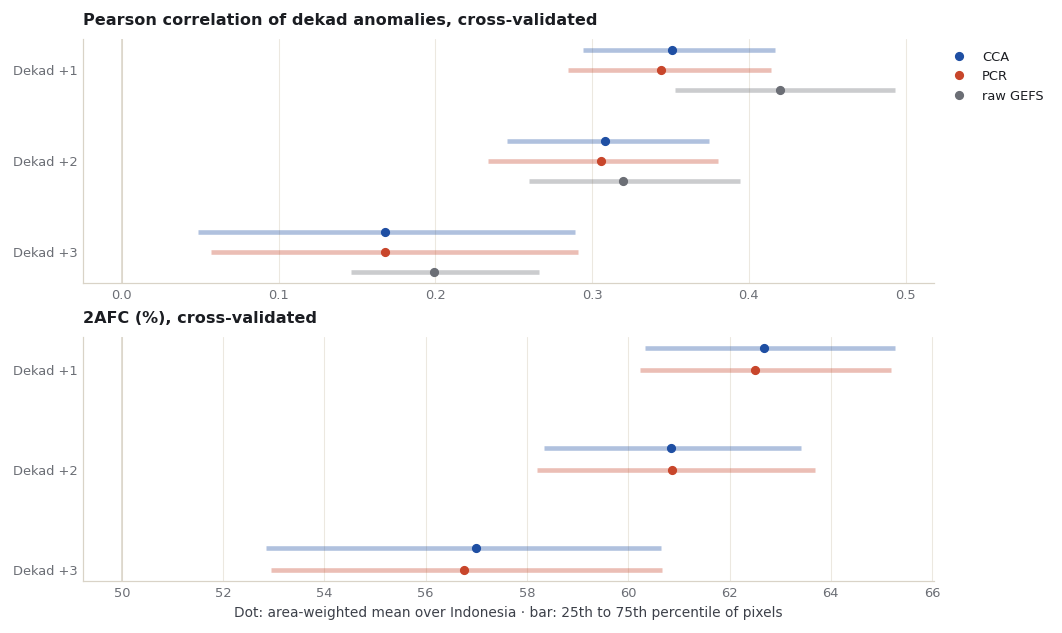

In [8]:
def quartiles(field):
    return np.nanpercentile(field.where(mask).values, [25, 75])


series = {"CCA": figures.ACCENT, "PCR": figures.MARK, "raw GEFS": figures.MUTED}
panels = [("Pearson", "skill_pearson", "Pearson correlation of dekad anomalies, cross-validated", 0),
          ("2AFC (%)", "skill_two_alternative_forced_choice", "2AFC (%), cross-validated", 50)]
fig, axes = plt.subplots(len(panels), 1, figsize=(figures.MAP_WIDTH, 5.6), layout="constrained")
for ax, (column, metric, title, reference) in zip(axes, panels):
    ax.axvline(reference, color=figures.LINE, linewidth=1)
    for k, (method, colour) in enumerate(series.items()):
        if method == "raw GEFS" and column != "Pearson":
            continue
        offset = (k - 1) * 0.22
        for lead in leads:
            field = raw_pearson[lead] if method == "raw GEFS" else clean(results[lead, method][metric])
            low, high = quartiles(field)
            ax.plot([low, high], [lead + offset] * 2, color=colour, linewidth=3, alpha=.35, solid_capstyle="butt")
            ax.plot(skill_by_lead.loc[(lead, method), column], lead + offset, "o", color=colour, markersize=5,
                    label=method if lead == 1 else None)
    ax.set_yticks(leads, [lead_names[lead] for lead in leads])
    ax.invert_yaxis()
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
axes[-1].set_xlabel("Dot: area-weighted mean over Indonesia · bar: 25th to 75th percentile of pixels")
assets = repo / "docs/assets/dekad-leads-2023"
assets.mkdir(parents=True, exist_ok=True)
fig.savefig(assets / "skill-by-lead.png")
plt.show()

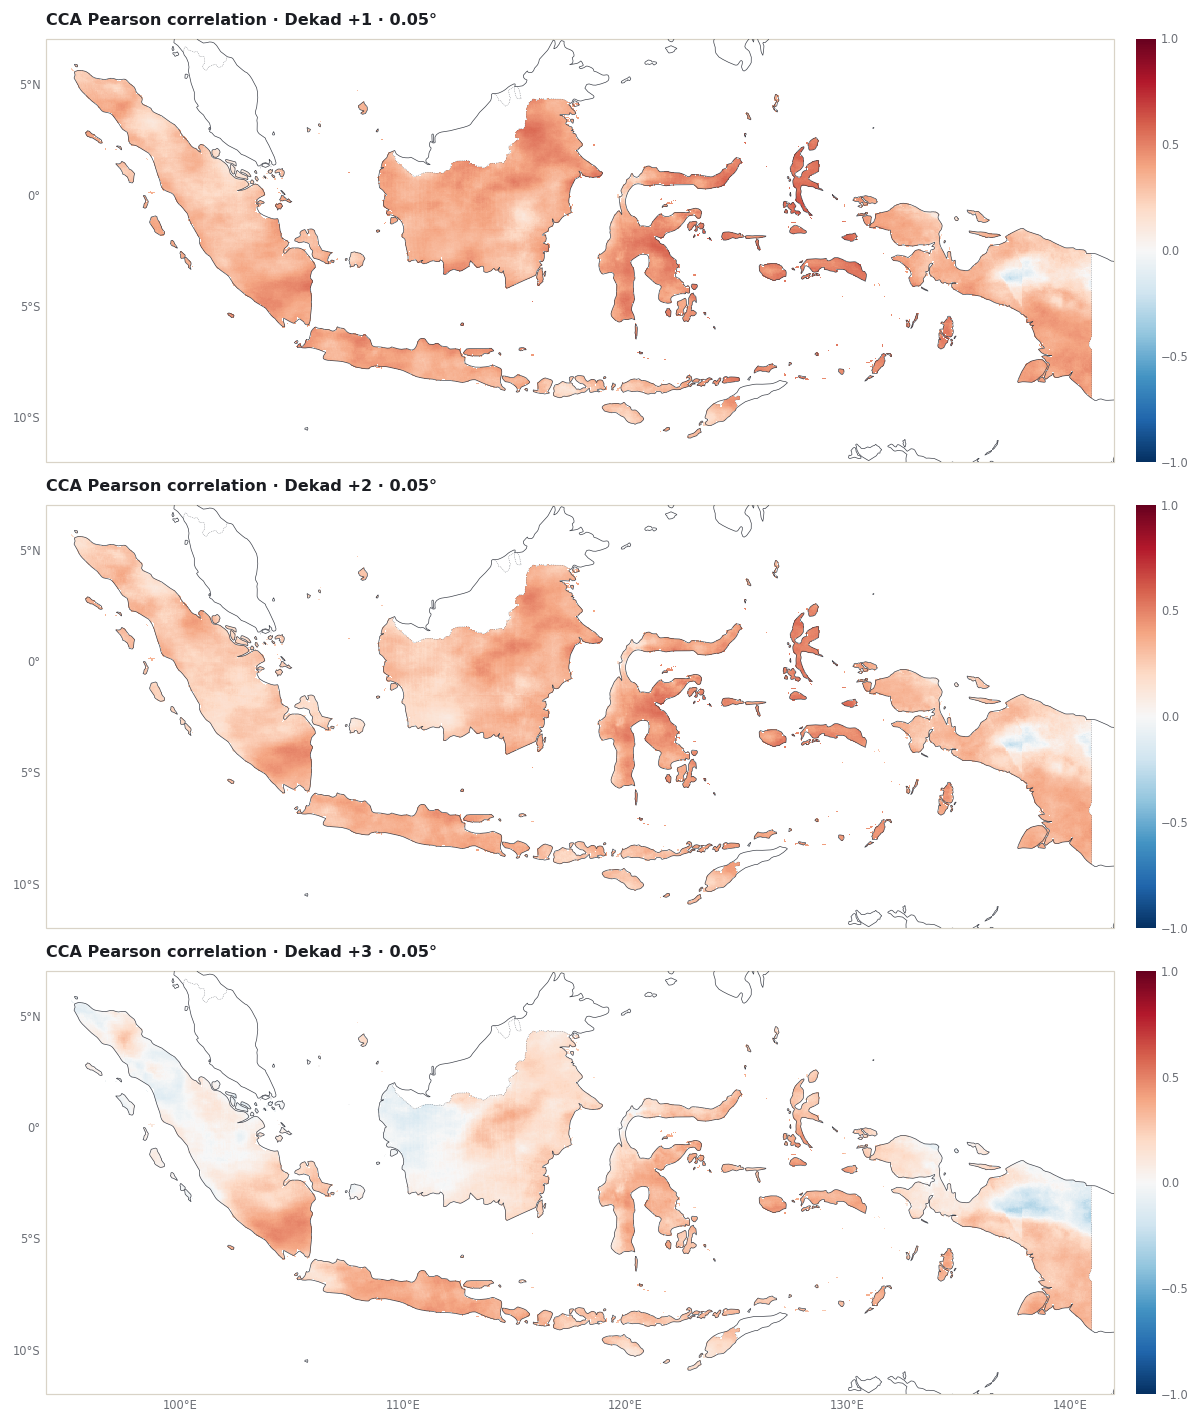

In [9]:
box = {"west": float(mask.X.min()) - .025, "east": float(mask.X.max()) + .025, "south": float(mask.Y.min()) - .025, "north": float(mask.Y.max()) + .025}
predictand_box = figures.extent_of(box)
fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    image = figures.draw_field(ax, clean(results[lead, "CCA"].skill_pearson), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"CCA Pearson correlation · {lead_names[lead]} · 0.05°")
    figures.colorbar(fig, image, ax, "", ticks=[-1, -.5, 0, .5, 1])
fig.savefig(assets / "cca-pearson-by-lead.png")
plt.show()

## 7. The 2023 forecasts, as issued

Each issue date gives a forecast for the next three dekads. A forecast **total** is
the observed 2000-2018 mean for that calendar dekad plus the calibrated anomaly;
where that sum is negative it is set to zero, and the cell counts how often.

CPT also gives tercile probabilities. It defines the categories from the training
samples it was given, all 171 dekads together, so the observed category uses the
same definition: at each pixel, below the 33rd or above the 67th percentile of the
171 training anomalies (NumPy's `hazen` rule, as in
[chapter 5](../learn/05-probabilistic-forecasts.ipynb)).

In [10]:
test_T = targets.target.values[~train]
observed = obs.isel(T=~train).where(mask)
clim_2023 = y_clim.isel(T=~train)
observed_anom = y_anom.isel(T=~train)
lo, hi = np.quantile(y_anom.isel(T=train).values, [0.33, 0.67], axis=0, method="hazen")
lower = xr.DataArray(lo, coords={"Y": mask["Y"], "X": mask["X"]}, dims=("Y", "X"))
upper = lower.copy(data=hi)
category = xr.where(observed_anom < lower, 0, xr.where(observed_anom > upper, 2, 1)).where(observed_anom.notnull())

forecast, clipped = {}, {}
for (lead, method), r in results.items():
    anomaly = clean(r.deterministic).assign_coords(T=test_T)
    total = clim_2023 + anomaly
    clipped[lead, method] = int((total < 0).sum())
    probability = clean(r.probabilistic).assign_coords(T=test_T)
    most_likely = probability.fillna(-1).argmax("C").where(probability.notnull().all("C") & mask)
    forecast[lead, method] = dict(total=total.clip(min=0).where(mask), probability=probability, most_likely=most_likely,
                                  top=probability.max("C").where(mask))
print("Forecast totals below zero before clipping (pixel-dekads), CCA:", {lead: clipped[lead, "CCA"] for lead in leads},
      f"of {int(mask.sum()) * len(test_T):,} per lead")

issues = {}
for r in design[design.kind == "forecast"].sort_values(["issued", "lead"]).itertuples():
    issues.setdefault(r.issued, []).append((r.lead, r.target, r.days))
print(f"{len(issues)} issue dates in 2023, {min(issues):%d %b} to {max(issues):%d %b}; complete issues (all {len(leads)} leads): "
      f"{sum(len(v) == len(leads) for v in issues.values())}")
for s, items in list(issues.items())[3:5]:
    print(f"  issued {s:%d %b}: " + ", ".join(f"+{lead} = {t:%d %b} ({days} days)" for lead, t, days in items))

Forecast totals below zero before clipping (pixel-dekads), CCA: {1: 3196, 2: 2507, 3: 1686} of 550,710 per lead
11 issue dates in 2023, 10 Sep to 20 Dec; complete issues (all 3 leads): 7
  issued 10 Oct: +1 = 11 Oct (10 days), +2 = 21 Oct (11 days), +3 = 01 Nov (10 days)
  issued 20 Oct: +1 = 21 Oct (11 days), +2 = 01 Nov (10 days), +3 = 11 Nov (10 days)


One issue date in full: the forecast issued on **31 October 2023** for the three
dekads of November, with the observation below each forecast. One column.

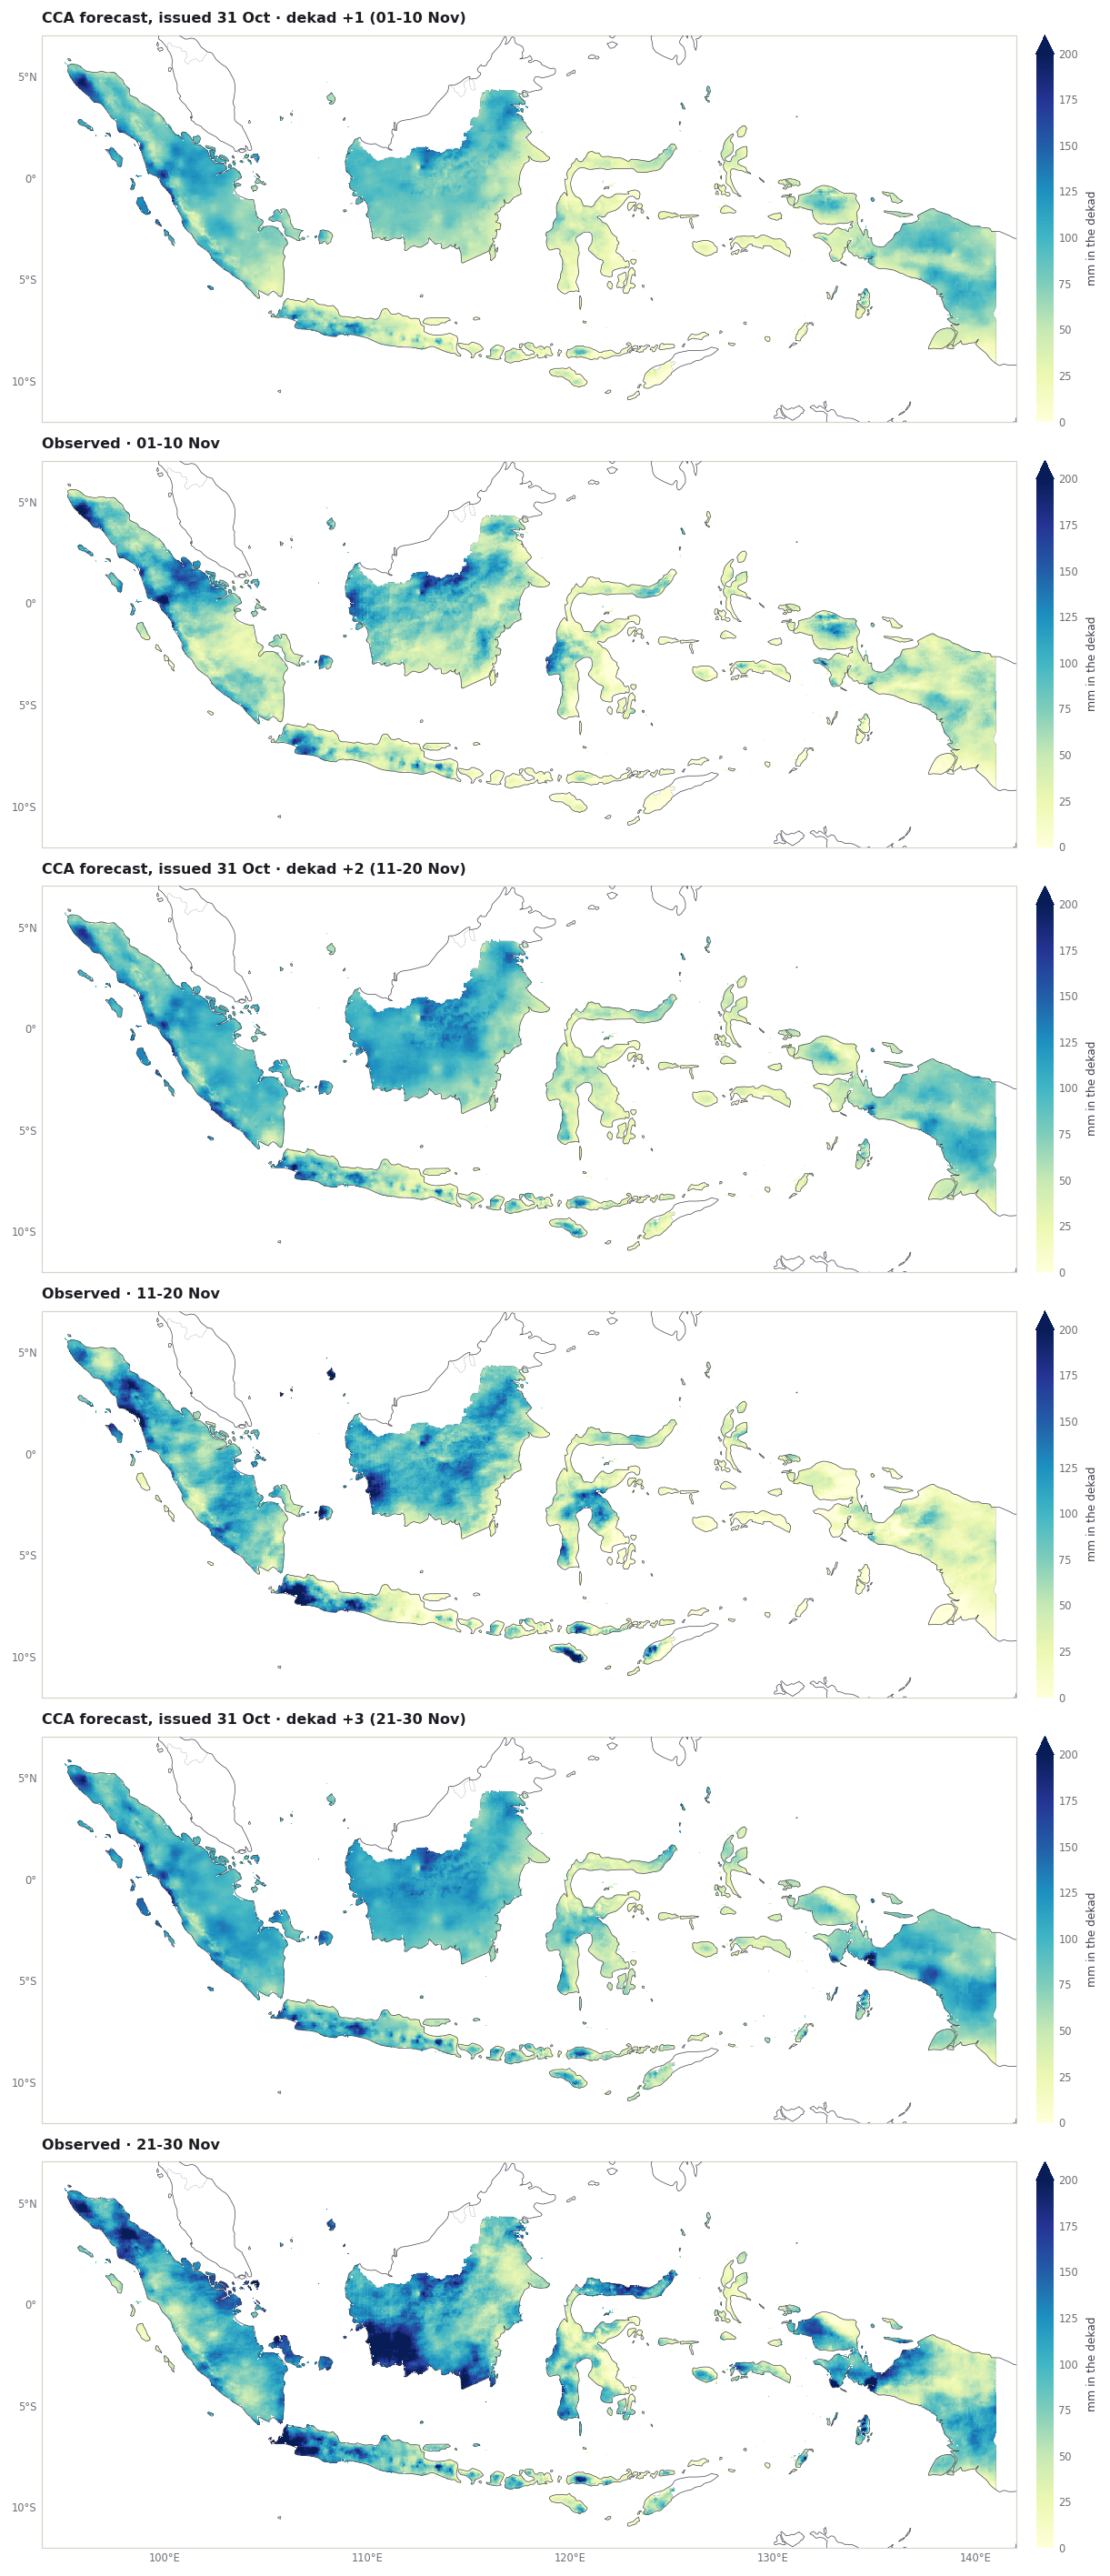

In [11]:
example = pd.Timestamp("2023-10-31")
fig, grid = figures.stacked([figures.map_height(predictand_box)] * (2 * len(leads)))
row = 0
for lead, target, days in issues[example]:
    end = target + pd.Timedelta(days=days - 1)
    for label, field in [(f"CCA forecast, issued 31 Oct · dekad +{lead} ({target:%d}-{end:%d %b})", forecast[lead, "CCA"]["total"].sel(T=target)),
                         (f"Observed · {target:%d}-{end:%d %b}", observed.sel(T=target))]:
        ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == 2 * len(leads) - 1)
        image = figures.draw_field(ax, field, cmap="YlGnBu", vmin=0, vmax=200)
        ax.set_title(label)
        figures.colorbar(fig, image, ax, "mm in the dekad", extend="max")
        row += 1
fig.savefig(assets / "issued-2023-10-31.png")
plt.show()

The same issue date in numbers: for each lead, the forecast and observed totals
averaged over Indonesia (area-weighted), the 2000-2018 mean, and how well the most
likely category matched what happened. One issue date is one outcome per lead, not a
skill estimate.

In [12]:
rows = []
for item in issues[example]:
    lead, target = item[0], item[1]
    days = item[2]
    end = target + pd.Timedelta(days=days - 1)
    obs_t, clim_t, cat_t = observed.sel(T=target), clim_2023.sel(T=target), category.sel(T=target)
    w = (weights * cat_t.notnull()).astype(float)
    shares = {name: float(w.where(cat_t == k, 0).sum() / w.sum() * 100) for k, name in enumerate(["below", "near", "above"])}
    for m in ["CCA", "PCR"]:
        f = forecast[lead, m]
        ml = f["most_likely"].sel(T=target)
        wm = w.where(ml.notnull(), 0)
        rows.append({"lead": lead, "name": lead_names[lead], "method": m, "target": f"{target:%d %b}-{end:%d %b %Y}",
                     "forecast mean (mm)": float(f["total"].sel(T=target).weighted(wm).mean()),
                     "observed mean (mm)": float(obs_t.weighted(wm).mean()),
                     "2000-2018 mean (mm)": float(clim_t.where(mask).weighted(wm).mean()),
                     "hit rate (%)": float(wm.where(ml == cat_t, 0).sum() / wm.sum() * 100),
                     "reference hit rate (%)": max(shares.values()),
                     **{f"observed {k} (%)": v for k, v in shares.items()},
                     **{f"forecast {name} (%)": float(wm.where(ml == k, 0).sum() / wm.sum() * 100)
                        for k, name in enumerate(["below", "near", "above"])}})
headline = pd.DataFrame(rows).set_index(["lead", "method"])
headline.round(1)

name              target  forecast mean (mm)  \
lead method                                                     
1    CCA     Dekad +1  01 Nov-10 Nov 2023                67.2   
     PCR     Dekad +1  01 Nov-10 Nov 2023                66.8   
2    CCA     Dekad +2  11 Nov-20 Nov 2023                79.5   
     PCR     Dekad +2  11 Nov-20 Nov 2023                79.2   
3    CCA     Dekad +3  21 Nov-30 Nov 2023                89.3   
     PCR     Dekad +3  21 Nov-30 Nov 2023                89.1   

             observed mean (mm)  2000-2018 mean (mm)  hit rate (%)  \
lead method                                                          
1    CCA                   60.3                 89.2          64.9   
     PCR                   60.3                 89.2          64.2   
2    CCA                   67.9                 98.3          64.1   
     PCR                   67.9                 98.3          63.3   
3    CCA                   94.2                 98.9          34.7   
     PCR                   94.2                 98.9          33.4   

             reference hit rate (%)  observed below (%)  observed near (%)  \
lead method                                                                  
1    CCA                       64.4                64.4               31.1   
     PCR                       64.4                64.4               31.1   
2    CCA                       64.4                64.4               27.6   
     PCR                       64.4                64.4               27.6   
3    CCA                       38.2                36.0               38.2   
     PCR                       38.2                36.0               38.2   

             observed above (%)  forecast below (%)  forecast near (%)  \
lead method                                                              
1    CCA                    4.5                97.9                1.9   
     PCR                    4.5                98.0                1.7   
2    CCA                    8.0                97.2                2.6   
     PCR                    8.0                92.1                5.8   
3    CCA                   25.9                80.9               12.4   
     PCR                   25.9                74.1               14.5   

             forecast above (%)  
lead method                      
1    CCA                    0.2  
     PCR                    0.3  
2    CCA                    0.2  
     PCR                    2.1  
3    CCA                    6.7  
     PCR                   11.5

Over all 9 dekads of October-December 2023, for each lead, scores over every pixel
and dekad (area-weighted):

- **Hit rate**: share where the most likely category was the one observed. The
  **reference** is the share of the most frequent observed category.
- **RPSS 2023**: ranked probability skill score against climatological odds
  (33/34/33%); above 0 is closer to what happened. Nine dekads of one season, not a
  skill estimate.
- **RMSE 2023**: error of the forecast totals in mm per dekad.

In [13]:
def rps(probability, cat):
    cumulative = probability.cumsum("C") / 100
    outcome = xr.concat([(cat <= k).astype(float) for k in range(3)], dim="C").assign_coords(C=probability["C"])
    return ((cumulative - outcome) ** 2).isel(C=slice(0, 2)).sum("C")


w3 = (weights * category.notnull()).astype(float)
reference = {name: float(w3.where(category == k, 0).sum() / w3.sum() * 100)
             for k, name in enumerate(["below normal", "near normal", "above normal"])}
rows = []
for (lead, method), f in forecast.items():
    w = w3.where(f["most_likely"].notnull(), 0)
    climatology = xr.DataArray([33.0, 34.0, 33.0], dims="C", coords={"C": f["probability"]["C"]}).broadcast_like(f["probability"])
    rows.append({"lead": lead, "name": lead_names[lead], "method": method,
                 "hit rate (%)": float(w.where(f["most_likely"] == category, 0).sum() / w.sum() * 100),
                 "reference hit rate (%)": max(reference.values()),
                 "RPSS 2023": float(1 - rps(f["probability"], category).weighted(w).mean()
                                    / rps(climatology, category).weighted(w).mean()),
                 "RMSE 2023 (mm)": float(np.sqrt(((f["total"] - observed) ** 2).weighted(w).mean())),
                 "mean forecast (mm)": float(f["total"].weighted(w).mean()),
                 "observed mean (mm)": float(observed.weighted(w).mean()),
                 **{f"forecast {name} (%)": float(w.where(f["most_likely"] == k, 0).sum() / w.sum() * 100)
                    for k, name in enumerate(["below", "near", "above"])}})
forecast_2023 = pd.DataFrame(rows).set_index(["lead", "method"]).sort_index()
print("Observed categories, share of area x dekads (%):", {k: round(v, 1) for k, v in reference.items()})
forecast_2023.round(2)

Observed categories, share of area x dekads (%): {'below normal': 53.8, 'near normal': 31.3, 'above normal': 14.9}


name  hit rate (%)  reference hit rate (%)  RPSS 2023  \
lead method                                                              
1    CCA     Dekad +1         52.73                    53.8       0.16   
     PCR     Dekad +1         52.38                    53.8       0.16   
2    CCA     Dekad +2         45.19                    53.8       0.08   
     PCR     Dekad +2         44.97                    53.8       0.07   
3    CCA     Dekad +3         50.55                    53.8       0.09   
     PCR     Dekad +3         49.35                    53.8       0.09   

             RMSE 2023 (mm)  mean forecast (mm)  observed mean (mm)  \
lead method                                                           
1    CCA              37.36               82.55               71.89   
     PCR              37.51               82.37               71.89   
2    CCA              40.23               85.87               71.89   
     PCR              40.59               85.72               71.89   
3    CCA              39.54               84.65               71.89   
     PCR              39.67               84.43               71.89   

             forecast below (%)  forecast near (%)  forecast above (%)  
lead method                                                             
1    CCA                  61.43              13.58               24.99  
     PCR                  61.83              12.87               25.30  
2    CCA                  55.99              18.67               25.34  
     PCR                  56.43              17.46               26.12  
3    CCA                  68.65              14.32               17.03  
     PCR                  65.36              13.13               21.51

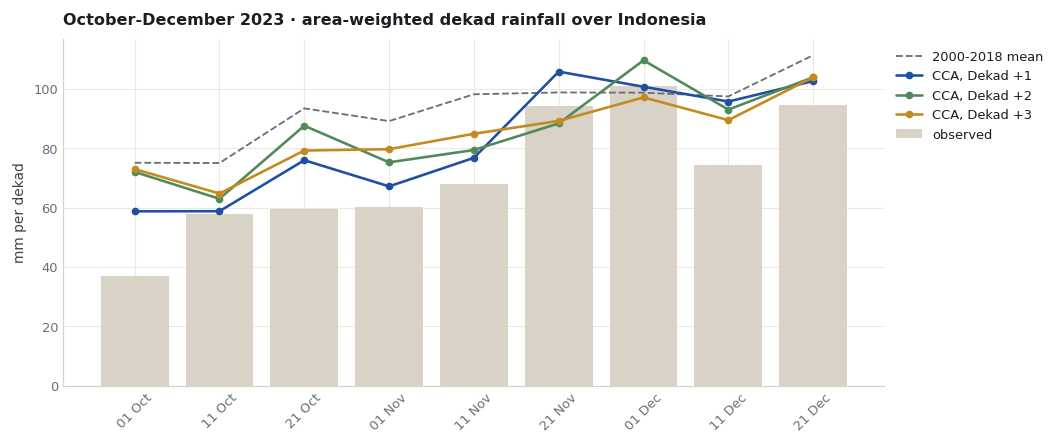

In [14]:
labels = [f"{pd.Timestamp(t):%d %b}" for t in test_T]
observed_series = observed.weighted(weights).mean(("Y", "X"))
clim_series = clim_2023.where(mask).weighted(weights).mean(("Y", "X"))
series_leads = [1, 2, 3]
fig, ax = plt.subplots(figsize=(figures.MAP_WIDTH, 3.9), layout="constrained")
x = np.arange(len(test_T))
ax.bar(x, observed_series, color=figures.LINE, label="observed")
ax.plot(x, clim_series, color=figures.MUTED, linestyle="--", linewidth=1.2, label="2000-2018 mean")
for lead, colour in zip(series_leads, [figures.ACCENT, figures.GREEN, figures.GOLD]):
    s = forecast[lead, "CCA"]["total"].weighted(weights).mean(("Y", "X"))
    ax.plot(x, s, "o-", color=colour, markersize=4, label=f"CCA, {lead_names[lead]}")
ax.set_xticks(x, labels, rotation=45)
ax.set_ylabel("mm per dekad")
ax.set_title("October-December 2023 · area-weighted dekad rainfall over Indonesia")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.savefig(assets / "ond-2023-series.png")
plt.show()

## 8. Save the results

Tables and figures for the story page, a NetCDF file of the skill maps, and the
fields of the interactive page: one small gzip-compressed binary file per map,
integers at a stated scale, stored only at the Indonesian pixels in the order of a
shared pixel list, read by the page only when a view needs them.

In [15]:
data_dir = repo / "docs/data/dekad-leads-2023"
data_dir.mkdir(parents=True, exist_ok=True)
for old in ["dekad-leads-2023-maps.nc"]:                     # the earlier 0.25 degree version of this case
    (data_dir / old).unlink(missing_ok=True)
(assets / "interactive-data.json").unlink(missing_ok=True)               # replaced by manifest.json and fields/
skill_by_lead.round(4).to_csv(data_dir / "skill-by-lead.csv")
headline.round(4).to_csv(data_dir / f"issued-{example:%Y-%m-%d}.csv")
forecast_2023.round(4).to_csv(data_dir / "ond-2023-dekad-forecasts.csv")
design.assign(**{c: design[c].dt.date for c in ["target", "end", "issued", "start"]}).to_csv(data_dir / "lead-design.csv", index=False)
area_rows = {"start": [str(pd.Timestamp(t).date()) for t in test_T], "observed": observed_series.values, "mean_2000_2018": clim_series.values}
for lead in leads:
    area_rows[f"cca_total_lead{lead}"] = forecast[lead, "CCA"]["total"].weighted(weights).mean(("Y", "X")).values
pd.DataFrame(area_rows).round(3).to_csv(data_dir / "ond-2023-area-totals.csv", index=False)
summary = {"target": "October-December 2023, dekads", "model": "GEFSv12 (IRI SubX GEFSv12_CPC)", "grid": "CHIRPS v3.0 dekad product, native 0.05 degree",
           "issue_rule": "issued on the last day of a dekad, 00 UTC run; forecasts dekads +1 to +3",
           "training_windows_days": {str(k): list(v) for k, v in gefs_source.WINDOWS.items()},
           "training_years": [training_years[0], training_years[-1]], "training_dekads_per_lead": int(train.sum()),
           "pixels": int(mask.sum()), "cross_validation_window": settings["crossvalidation_window"],
           "settings": {k: str(v) for k, v in cca_settings.items()},
           "observed_category_percent_2023": {k: round(v, 2) for k, v in reference.items()},
           "fit_minutes": {f"{lead}-{m}": round(r.attrs["fit_seconds"] / 60, 1) for (lead, m), r in results.items()},
           "clipped_pixel_dekads": {f"{lead}-{m}": n for (lead, m), n in clipped.items()}}
(data_dir / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
maps = xr.Dataset()
for lead in leads:
    for m in ["CCA", "PCR"]:
        maps[f"{m.lower()}_pearson_lead{lead}"] = clean(results[lead, m].skill_pearson).drop_vars(
            [c for c in results[lead, m].skill_pearson.coords if c not in ("Y", "X")], errors="ignore").astype("float32")
    maps[f"raw_pearson_lead{lead}"] = raw_pearson[lead].astype("float32")
_ = save_netcdf(maps, data_dir / "dekad-leads-2023-skill-maps.nc", overwrite=True,
            metadata={"note": "Dekad rainfall, GEFSv12 dekads +1 to +3: cross-validated correlation 2000-2018 at 0.05 degree"})

In [16]:
# Interactive fields: one gzip-compressed binary file per map
field_dir = assets / "fields"
field_dir.mkdir(exist_ok=True)
for old in field_dir.glob("*"):
    old.unlink()
flat = np.flatnonzero(mask.transpose("Y", "X").values.ravel())          # row 0 = northernmost pixel row
n = len(flat)
lead_key = {lead: f"dekad{lead}" for lead in leads}


def at_pixels(a):
    return np.asarray(a.transpose("Y", "X").values, dtype="float64").ravel()[flat]


def encode(values, kind, scale):
    v = np.round(values * scale)
    if kind == "i16":
        return np.where(np.isfinite(v), np.clip(v, -32767, 32767), -32768).astype("<i2").tobytes()
    if kind == "u16":
        return np.where(np.isfinite(v), np.clip(v, 0, 65534), 65535).astype("<u2").tobytes()
    return np.where(np.isfinite(v), np.clip(v, 0, 254), 255).astype("u1").tobytes()


def write(name, parts):
    (field_dir / f"{name}.bin.gz").write_bytes(gzip.compress(b"".join(encode(*p) for p in parts), 9, mtime=0))


(assets / "pixels.bin").write_bytes(flat.astype("<i4").tobytes())
for lead in leads:
    for m in ["CCA", "PCR"]:
        write(f"skill-{m}-pearson-{lead_key[lead]}", [(at_pixels(clean(results[lead, m].skill_pearson)), "i16", 1000)])
        write(f"skill-{m}-twoafc-{lead_key[lead]}", [(at_pixels(clean(results[lead, m].skill_two_alternative_forced_choice)), "i16", 10)])
    write(f"skill-raw-pearson-{lead_key[lead]}", [(at_pixels(raw_pearson[lead]), "i16", 1000)])
days_of = dict(zip(targets.target, targets.days))
for t in test_T:
    stamp = f"{pd.Timestamp(t):%Y-%m-%d}"
    write(f"obs-{days_of[pd.Timestamp(t)]}-{stamp}", [(at_pixels(observed.sel(T=t)), "u16", 10), (at_pixels(clim_2023.sel(T=t).where(mask)), "u16", 10),
                                                       (at_pixels(category.sel(T=t)), "u8", 1)])
for (lead, m), f in forecast.items():
    for t in test_T:
        stamp = f"{pd.Timestamp(t):%Y-%m-%d}"
        write(f"fc-{lead_key[lead]}-{m}-{stamp}", [(at_pixels(f["total"].sel(T=t)), "u16", 10), (at_pixels(f["most_likely"].sel(T=t)), "u8", 1),
                                                   (at_pixels(f["top"].sel(T=t)), "u8", 1)])


def records(frame):
    return [{k: (None if isinstance(v, float) and not np.isfinite(v) else v) for k, v in row.items()}
            for row in frame.to_dict(orient="records")]


top = float(np.ceil(np.nanpercentile(np.concatenate([observed.values.ravel()] + [forecast[k]["total"].values.ravel() for k in forecast]), 99) / 50) * 50)
manifest = {
    "grid": {"west": round(float(mask.X.min()) - .025, 3), "north": round(float(mask.Y.max()) + .025, 3), "step": 0.05,
             "nx": int(mask.sizes["X"]), "ny": int(mask.sizes["Y"]), "pixels": n},
    "leads": leads, "leadKeys": [lead_key[lead] for lead in leads], "leadNames": [lead_names[lead] for lead in leads],
    "methods": ["CCA", "PCR"], "rawName": "raw GEFS", "training": "2000-2018",
    "sample": "the 171 training dekads of 2000-2018", "cellText": f"Indonesia's {n:,} pixels at 0.05°",
    "layout": {"skill": [["value", "i16"]], "obs": [["total", "u16", 10], ["mean", "u16", 10], ["category", "u8", 1]],
               "fc": [["total", "u16", 10], ["category", "u8", 1], ["probability", "u8", 1]]},
    "scales": {"pearson": 1000, "twoafc": 10},
    "rainMax": {"8": top, "9": top, "10": top, "11": top}, "rainLegend": "mm in the dekad", "axisDays": 35,
    "timelineTitle": "the next three dekads",
    "timelineHint": "Issued at 00 UTC on the last day of a dekad. Bars are the target dekads in days after the issue date; hover for dates.",
    "mapsHint": "Dekad +1 at the top. Totals are the 2000-2018 mean for that calendar dekad plus the calibrated anomaly; categories follow CPT's terciles of the training anomalies.",
    "seriesHint": "Bars: observed. Dashed: 2000-2018 mean. Lines: CCA forecast totals made one, two and three dekads ahead.",
    "issues": [{"issued": f"{s:%Y-%m-%d}", "label": f"{s:%d %b %Y}",
                "targets": [{"lead": lead_key[lead], "start": f"{t:%Y-%m-%d}", "days": int(days)} for lead, t, days in items]}
               for s, items in issues.items()],
    "skillTable": records(skill_by_lead.reset_index().round(4)),
    "scores2023": records(forecast_2023.reset_index().round(3)),
    "headline": {"issued": f"{example:%Y-%m-%d}", "rows": records(headline.reset_index().round(3))},
    "series": pd.DataFrame(area_rows).round(2).to_dict(orient="list"),
    "seriesLeads": [lead_key[lead] for lead in series_leads], "seriesUnit": "mm per dekad",
    "seriesTitle": "October-December 2023 · area-weighted dekad rainfall over Indonesia",
}
(assets / "manifest.json").write_text(json.dumps(manifest, separators=(",", ":"), allow_nan=False) + "\n")
sizes = sorted(p.stat().st_size for p in field_dir.iterdir())
print(f"{n:,} pixels; {len(sizes)} field files, {sum(sizes) / 1e6:.1f} MB in total (largest {sizes[-1] / 1e3:.0f} kB); "
      f"manifest {(assets / 'manifest.json').stat().st_size / 1e3:.0f} kB; colour scale up to {top:.0f} mm")
for f in sorted(data_dir.iterdir()) + sorted(p for p in assets.iterdir() if p.is_file()):
    print(f"{f.relative_to(repo)}  ({f.stat().st_size / 1000:.0f} kB)")

61,190 pixels; 78 field files, 9.2 MB in total (largest 188 kB); manifest 9 kB; colour scale up to 200 mm
docs/data/dekad-leads-2023/dekad-leads-2023-skill-maps.nc  (2031 kB)
docs/data/dekad-leads-2023/issued-2023-10-31.csv  (1 kB)
docs/data/dekad-leads-2023/lead-design.csv  (37 kB)
docs/data/dekad-leads-2023/ond-2023-area-totals.csv  (0 kB)
docs/data/dekad-leads-2023/ond-2023-dekad-forecasts.csv  (1 kB)
docs/data/dekad-leads-2023/skill-by-lead.csv  (0 kB)
docs/data/dekad-leads-2023/summary.json  (1 kB)
docs/assets/dekad-leads-2023/cca-pearson-by-lead.png  (852 kB)
docs/assets/dekad-leads-2023/issued-2023-10-31.png  (1949 kB)
docs/assets/dekad-leads-2023/manifest.json  (9 kB)
docs/assets/dekad-leads-2023/ond-2023-series.png  (99 kB)
docs/assets/dekad-leads-2023/pixels.bin  (245 kB)
docs/assets/dekad-leads-2023/skill-by-lead.png  (67 kB)


## References {.unnumbered .reference-section}

1. IRI Data Library. *SubX EMC GEFSv12_CPC* (hindcast and forecast precipitation). <https://iridl.ldeo.columbia.edu/SOURCES/.Models/.SubX/.EMC/.GEFSv12_CPC/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
2. Guan, H., Zhu, Y., Sinsky, E., et al. (2022). GEFSv12 reforecast dataset for supporting subseasonal and hydrometeorological applications. *Monthly Weather Review*, 150(3), 647-665. <https://doi.org/10.1175/MWR-D-21-0245.1>
3. BMKG. *Peringatan Dini Curah Hujan Dasarian* (dekadal rainfall early warnings by regency and city; showed dasarian I November 2026 when checked on 10 November 2026). <https://www.bmkg.go.id/iklim/peringatan-dini-hujan-tinggi>
4. Climate Hazards Center, UC Santa Barbara. *CHIRPS: Rainfall Estimates from Rain Gauge and Satellite Observations* (CHIRPS version 3.0 page). <https://www.chc.ucsb.edu/data/chirps3>
5. Funk, C., Peterson, P., Landsfeld, M., et al. (2014). *A quasi-global precipitation time series for drought monitoring*. U.S. Geological Survey Data Series 832. <https://doi.org/10.3133/ds832>
6. IRI. *PyCPT 2.10.4 source: `pycpt/src/cptcore/functional/cca.py`* (`canonical_correlation_analysis`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptcore/functional/cca.py>
7. IRI. *PyCPT 2.10.4 source: `pycpt/src/cptextras/redate.py`* (`redate`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptextras/redate.py>
8. Natural Earth. *Admin 0: Countries*, 1:10m cultural vectors. <https://www.naturalearthdata.com/downloads/10m-cultural-vectors/10m-admin-0-countries/>
9. Shapely. *shapely.contains_xy*. <https://shapely.readthedocs.io/en/stable/reference/shapely.contains_xy.html>
10. NumPy. *numpy.quantile* (NumPy manual). <https://numpy.org/doc/stable/reference/generated/numpy.quantile.html>
11. Mason, S. J., and Weigel, A. P. (2009). A generic forecast verification framework for administrative purposes. *Monthly Weather Review*, 137(1), 331-349. <https://doi.org/10.1175/2008MWR2553.1>
12. Epstein, E. S. (1969). A scoring system for probability forecasts of ranked categories. *Journal of Applied Meteorology*, 8(6), 985-987. <https://doi.org/10.1175/1520-0450(1969)008%3C0985:ASSFPF%3E2.0.CO;2>
13. SciTools. *Cartopy* (documentation). <https://scitools.org.uk/cartopy/docs/latest/>